**本篇通过学习框架简洁实现权重衰减**

In [4]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l
#模型的超参数
batch_size = 5
num_epochs = 100
lambd = 0
lr = 0.003
#数据集生成参数
input_dim = 200
out_dim = 1
true_w = torch.ones((input_dim, 1)) *0.01
true_b = 0.05
#数据集和迭代器
num_train =20
num_test = 100
train_data = d2l.synthetic_data(true_w, true_b, num_train)
test_data = d2l.synthetic_data(true_w, true_b, num_test)
train_iter = d2l.load_array(train_data, batch_size, is_train=True)
test_iter = d2l.load_array(test_data, batch_size, is_train=False)
#神经网络、损失函数
net = nn.Sequential(nn.Linear(input_dim, out_dim))
loss = nn.MSELoss(reduction = 'none')

In [8]:
def train(lambd):
    trainer = torch.optim.SGD([
        {"params":net[0].weight,'weight_decay': lambd},
        {"params":net[0].bias}], lr=lr)
    animator = d2l.Animator(xlabel='epochs', ylabel='loss', yscale='log',
                            xlim=[5, num_epochs], legend=['train', 'test'])
    for p in net.parameters(): p.data.normal_()
    for epoch in range(num_epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.mean().backward()
            trainer.step()
        if (epoch + 1) % 5 == 0:
            animator.add(epoch + 1,
                         (d2l.evaluate_loss(net, train_iter, loss),
                          d2l.evaluate_loss(net, test_iter, loss)))
    print('w的L2范数: ', net[0].weight.norm().item())


> 下面我们将使用 lambd = 1, 2, 4, 8, 16 进行实验，观察其对模型训练的影响

w的L2范数:  4.011134624481201


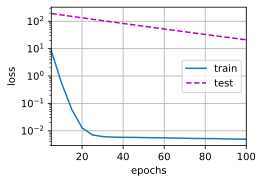

In [14]:
train(1)

w的L2范数:  1.1305636167526245


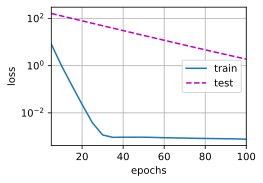

In [10]:
train(2)

w的L2范数:  0.11682812124490738


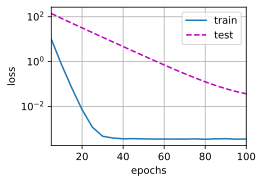

In [11]:
train(4)

w的L2范数:  0.09974795579910278


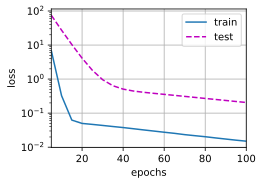

In [12]:
train(8)

w的L2范数:  0.021085232496261597


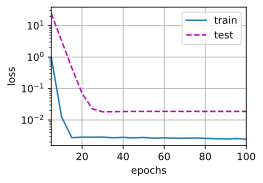

In [13]:
train(16)